## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 3 | BÀI 2

---

# **PHÂN PHỐI CHUẨN LỆCH VÀ PHÂN PHỐI SKEW-T**

|  |  |
|:---|:---|
|**Thời gian đọc** | 60 phút |
|**Kiến thức nền** | Thống kê cơ bản  |
|**Từ khóa** | Độ lệch (skewness), độ nhọn (kurtosis), phân phối chuẩn lệch, phân phối skew-t |


---

*Ở bài trước, chúng ta đã xem lại các khái niệm về biến ngẫu nhiên và ôn lại những điều cơ bản của một số phân phối xác suất thông dụng. Phân phối được dùng nhiều nhất trong nhiều ứng dụng là phân phối chuẩn. Phân phối chuẩn có hình dạng đối xứng và các tính chất dễ dùng cho phân tích dữ liệu. Tuy nhiên, trong thế giới thực, dữ liệu quan sát không phải lúc nào cũng có phân phối hình chuông. Dữ liệu có thể tập trung ở bên phải hoặc bên trái của toàn bộ khoảng dữ liệu. Ta thường gọi loại phân phối dữ liệu này là lệch phải hoặc lệch trái. Trong bài này, ta sẽ xem xét dữ liệu lệch và học cách đo độ lệch. Ngoài độ lệch, ta cũng sẽ học đuôi dày hay đuôi mỏng của một phân phối dữ liệu là gì và cách đo nó. Sau đó, ta sẽ giới thiệu phân phối chuẩn lệch và các họ của nó. Đây là phân phối cho dữ liệu quan sát có một số tính chất của phân phối chuẩn nhưng không có hình dạng đối xứng hoặc dạng đuôi tương tự. Xuyên suốt bài này, ta sẽ dùng lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm và lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones cho từng kỹ thuật ta đề cập.*

In [7]:
# Tải thư viện
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.stats import kurtosis, skewnorm

plt.rcParams["figure.figsize"] = (16, 9)  # Kích thước hình

In [8]:
# Tải bộ dữ liệu
data_set = pd.read_csv("M3. bond_and_stock_data.csv")

## **1. Độ lệch (Skewness)**

Phân phối lệch nghĩa là phân phối xác suất không đối xứng. Ta thường vẽ biểu đồ tần suất (histogram) từ bộ dữ liệu để kiểm tra độ lệch. Ở hình 1 bên dưới, đồ thị gồm ba biểu đồ tần suất. Biểu đồ ở giữa là biểu đồ tần suất của một bộ dữ liệu lấy mẫu từ phân phối chuẩn. Phân phối chuẩn là phân phối đối xứng. Ta nhận thấy đỉnh nằm ở giữa phân phối. Biểu đồ tần suất ở phía dưới bên trái của hình cho thấy phân phối lệch phải. Phân phối lệch phải có đuôi dài hơn, kéo dài về bên phải của biểu đồ. Đỉnh của phân phối lệch phải nằm ở vùng bên trái của phân phối. Cuối cùng, biểu đồ tần suất ở phía dưới bên phải của hình là của phân phối lệch trái. Phân phối lệch trái có đuôi dài hơn, kéo dài về bên trái của biểu đồ. Đỉnh của phân phối lệch trái nằm ở vùng bên phải của phân phối.

**Hình 1: Biểu đồ tần suất của phân phối chuẩn, phân phối lệch phải và phân phối lệch trái**

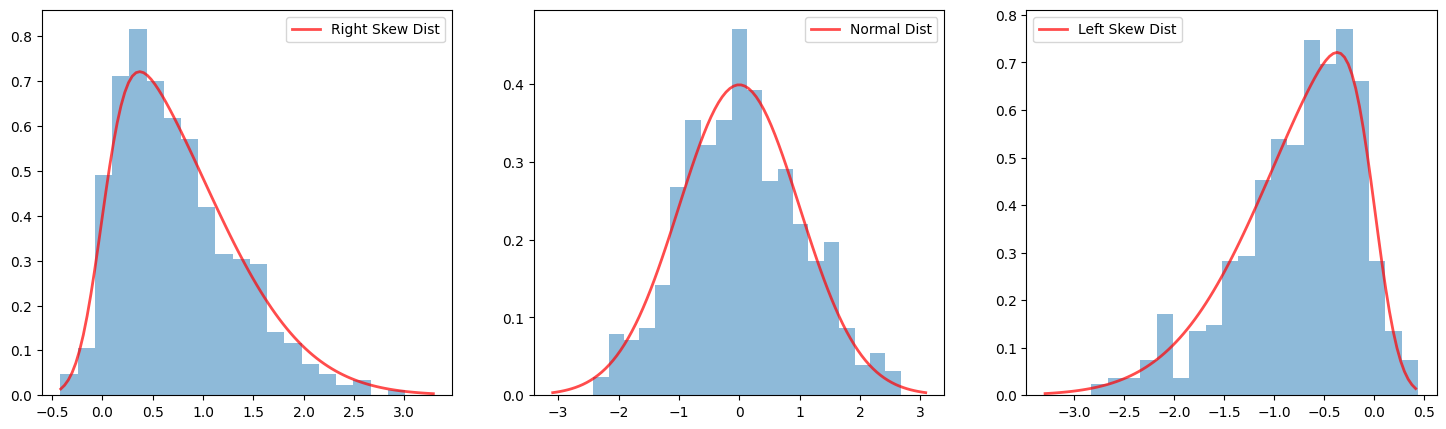

In [9]:
# Biểu đồ tần suất của phân phối chuẩn, lệch phải và lệch trái


# Hàm hỗ trợ HistogramPlot
def HistogPlot(a, label):
    # np.random.seed(12345)
    r = skewnorm.rvs(a, size=500)
    x = np.linspace(skewnorm.ppf(0.001, a), skewnorm.ppf(0.999, a), 100)
    plt.plot(x, skewnorm.pdf(x, a), "r-", lw=2, alpha=0.7, label=label)  # Mật độ
    plt.hist(r, bins=20, density=True, histtype="stepfilled", alpha=0.5)  # Biểu đồ tần suất
    plt.legend()


# Vẽ biểu đồ
plt.figure(figsize=(18, 5))
ax1 = plt.subplot(131)
HistogPlot(5, "Phân phối lệch phải")  # Lệch phải a>0
ax2 = plt.subplot(132)
HistogPlot(0, "Phân phối chuẩn")  # Phân phối chuẩn a=0
ax3 = plt.subplot(133)
HistogPlot(-5, "Phân phối lệch trái")  # Lệch trái a<0
plt.show()

Một cách nhanh để kiểm tra dữ liệu có bị lệch hay không là kiểm tra thứ tự của trung bình, trung vị và yếu vị (mode) của dữ liệu. **Trung bình (mean)** là giá trị trung bình của dữ liệu. **Trung vị (median)** là giá trị của (các) điểm dữ liệu ở phân vị thứ 50 của dữ liệu đã sắp xếp từ nhỏ nhất đến lớn nhất. **Yếu vị (mode)** là giá trị của dữ liệu xuất hiện thường xuyên nhất trong bộ dữ liệu. Hình 2 bên dưới cho thấy các quan hệ khác nhau giữa ba chỉ số này đối với phân phối đối xứng, lệch phải và lệch trái.

**Hình 2: Quan hệ giữa trung bình, trung vị và yếu vị đối với phân phối đối xứng, lệch phải và lệch trái**

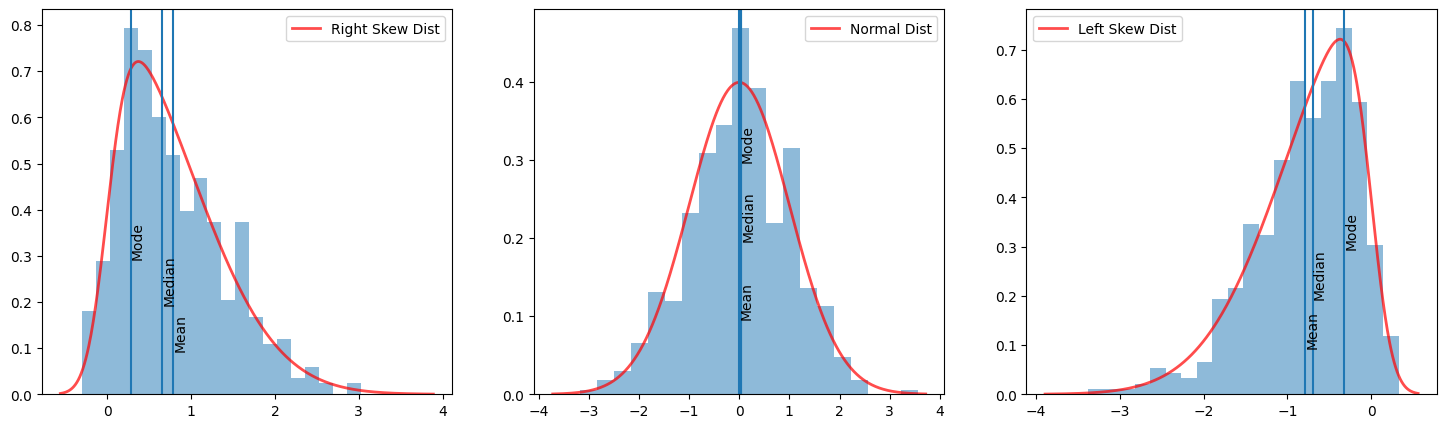

In [10]:
# Quan hệ giữa trung bình, trung vị và yếu vị cho phân phối đối xứng, lệch phải và lệch trái


# Hàm hỗ trợ HistogramPlot
def HistogPlot(a, label):
    np.random.seed(123)
    r = skewnorm.rvs(a, size=500)
    x = np.linspace(skewnorm.ppf(0.0001, a), skewnorm.ppf(0.9999, a), 500)
    plt.plot(x, skewnorm.pdf(x, a), "r-", lw=2, alpha=0.7, label=label)  # Mật độ
    n, bins, patches = plt.hist(
        r, bins=20, density=True, histtype="stepfilled", alpha=0.5
    )  # Biểu đồ tần suất

    # Thêm trung bình
    plt.axvline(x=np.mean(r))
    plt.text(np.mean(r), 0.1, "Trung bình", rotation=90)

    # Thêm trung vị
    plt.axvline(x=np.median(r))
    plt.text(np.median(r), 0.2, "Trung vị", rotation=90)

    # Thêm yếu vị (theo khoảng có tần suất cao nhất)
    plt.axvline(x=(bins[n.argmax()] + bins[n.argmax() + 1]) / 2)
    plt.text((bins[n.argmax()] + bins[n.argmax() + 1]) / 2, 0.3, "Yếu vị", rotation=90)
    plt.legend()


# Vẽ biểu đồ
plt.figure(figsize=(18, 5))
ax1 = plt.subplot(131)
HistogPlot(5, "Phân phối lệch phải")
ax2 = plt.subplot(132)
HistogPlot(0, "Phân phối chuẩn")
ax3 = plt.subplot(133)
HistogPlot(-5, "Phân phối lệch trái")
plt.show()

Như ta vừa thấy, ta có thể đánh giá độ lệch của một bộ dữ liệu bằng mắt qua biểu đồ tần suất. Ngoài ra, ta cũng có thể dùng quan hệ giữa trung bình, trung vị và yếu vị để quyết định dữ liệu có lệch hay không. Tuy nhiên, có thước đo nào cho ta biết một bộ dữ liệu có lệch hay không? Có, có những thước đo có thể cho ta biết bộ dữ liệu có lệch hay không. Đây là một thước đo phổ biến từ nhiều giáo trình.

Hệ số moment chuẩn hóa Fisher-Pearson (độ lệch):

$$ \sum_{i=1}^{n}\frac{(X_{i}-\bar{X})^{3}/n}{s_{X}^{3}} $$

Trong đó $\bar{X}$ là trung bình của $X$ và s là độ lệch chuẩn của $X$

Các tính chất của hệ số kiểm tra này là:

> 1. Phân phối đối xứng sẽ có giá trị = $0$. Giá trị âm cho biết phân phối lệch trái. Giá trị dương cho biết phân phối lệch phải.
> 2. Hệ số này so sánh dữ liệu với phân phối chuẩn. Giá trị của hệ số càng lớn thì dữ liệu càng lệch khỏi phân phối chuẩn.
> 3. Chỉ số có thể được điều chỉnh theo cỡ mẫu bằng cách nhân với $\frac{\sqrt{n(n-1)}}{n-2}$. Khi cỡ mẫu lớn, hệ số điều chỉnh này tiến về $1$.

Hầu hết phần mềm thống kê có thể tính độ lệch cho ta, do đó ta không phải tính con số này bằng tay.

## **2. Độ nhọn (Kurtosis)**

Độ nhọn là một thước đo khác dùng để quyết định hình dạng phân phối của bộ dữ liệu. Độ nhọn cho phép ta quyết định đuôi của một phân phối dày hơn hay mỏng hơn đuôi của phân phối chuẩn. Đuôi dày nghĩa là gì? Nhìn chung, phân phối có đuôi béo hơn hoặc dài hơn phân phối chuẩn sẽ được gọi là phân phối đuôi dày. Ở hình 3 bên dưới, ta sẽ cho thấy ba phân phối khác nhau với các hình dạng đuôi khác nhau.

**Hình 3: Các hàm xác suất với đuôi khác nhau so với phân phối chuẩn**

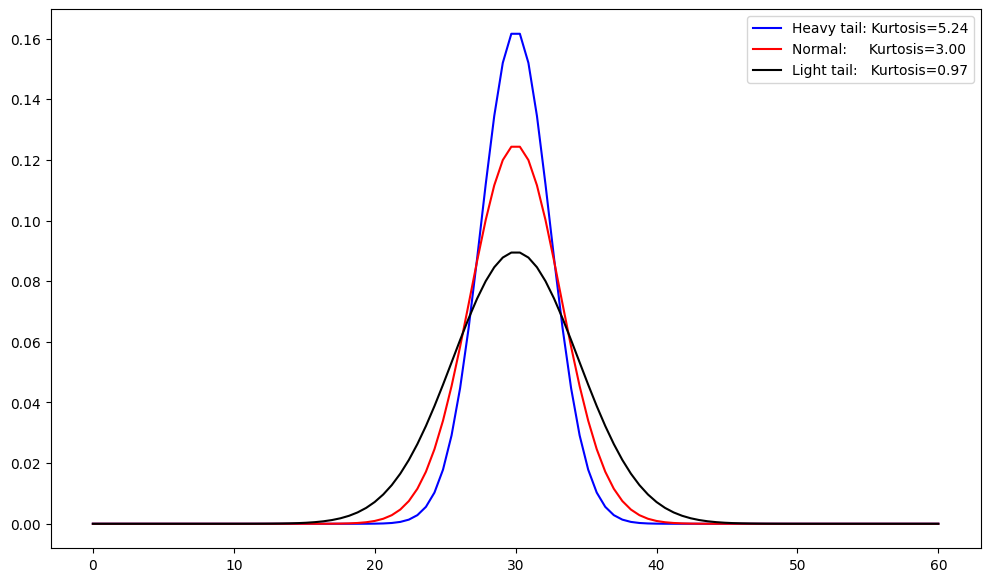

In [11]:
# Ba phân phối với hình dạng đuôi khác nhau
x = np.linspace(0, 60, 100)
y1 = stats.norm.pdf(x, loc=30, scale=2.450)
y2 = stats.norm.pdf(x, loc=30, scale=3.194)
y3 = stats.norm.pdf(x, loc=30, scale=4.450)

# Vẽ từng phân phối
plt.figure(figsize=(12, 7))
plt.plot(x, y1, c="b", label="Đuôi dày: Độ nhọn={:.2f}".format(kurtosis(y1)))
plt.plot(x, y2, c="r", label="Chuẩn:      Độ nhọn={:.2f}".format(kurtosis(y2)))
plt.plot(x, y3, c="k", label="Đuôi mỏng:  Độ nhọn={:.2f}".format(kurtosis(y3)))
plt.legend()
plt.show()

Từ hình 3, đường cong màu đỏ là phân phối chuẩn. Ta thấy cả ba phân phối đều là phân phối đối xứng tập trung quanh 30. Tuy nhiên, so với phân phối chuẩn, phân phối đường cong màu xanh dương có đỉnh cao hơn quanh 30. Điều này nghĩa là đường cong xanh dương gán xác suất cao hơn phân phối chuẩn quanh 30. Tuy nhiên, phân phối đường cong xanh dương gán xác suất ít hơn phân phối chuẩn ở vùng (20, 26) và (34, 40). Ngoài ra, phân phối đường cong xanh dương có xác suất cao hơn phân phối chuẩn ở cả hai đầu của đường cong. **Đỉnh cao hơn, thân gầy hơn và đuôi dài hơn phân phối chuẩn làm phân phối đường cong xanh dương là phân phối đuôi dày**. Mặt khác, phân phối đường cong đen có đỉnh thấp hơn phân phối chuẩn quanh 30. Phân phối đường cong đen có xác suất cao hơn phân phối chuẩn ở vùng (16, 26) và (34, 44) và có xác suất thấp hơn cùng đuôi ngắn hơn ở cả hai đầu của đường cong so với phân phối chuẩn. **Đỉnh thấp hơn, thân béo hơn và đuôi ngắn hơn phân phối chuẩn làm phân phối đường cong đen là phân phối đuôi mỏng**.

Theo hình dạng đuôi của phân phối đối xứng, phân phối chuẩn gọi là **mesokurtic**. Phân phối đuôi béo gọi là **leptokurtic**. Phân phối đuôi mỏng gọi là **platykurtic**.

Có một công thức chính thức của độ nhọn như sau:

$$  \text{Độ nhọn} = \sum_{i=1}^{n} \frac{(X_{i}-\bar{X})^{4}/N}{s^{4}}$$

Phân phối chuẩn có độ nhọn = $3$. Phân phối đuôi béo có độ nhọn > $3$. Phân phối đuôi mỏng có độ nhọn < $3$. Mọi ứng dụng thống kê đều có hàm tính độ nhọn. Một số ứng dụng thống kê có thể dùng độ nhọn vượt (excess kurtosis) để chỉ độ nhọn. **Độ nhọn vượt (excess kurtosis)** là $\textit{độ nhọn} – 3$. Khi một phân phối có độ nhọn vượt = $0$, phân phối này là phân phối chuẩn. Hãy chắc chắn kiểm tra sách hướng dẫn của ứng dụng thống kê đã chọn để xác minh định nghĩa độ nhọn được dùng trong ứng dụng.

Cả độ lệch và độ nhọn đều nhằm giúp ta hiểu rõ hơn hình dạng của một phân phối dữ liệu. Nếu muốn kiểm tra một bộ dữ liệu có phân phối chuẩn hay không, ta có thể vẽ đồ thị và kiểm tra độ lệch và độ nhọn của nó. Tuy nhiên, cách tốt nhất là tiến hành kiểm định Shapiro–Wilk, như mô tả ở bài trước.

## **3. Phân phối chuẩn lệch và phân phối Skew-t**

Ở các phần trước, ta đã nói về dữ liệu lệch và dữ liệu đuôi dày. Ta đã học ở Module 1 rằng ta có thể biến đổi dữ liệu không có phân phối chuẩn thành dữ liệu có phân phối chuẩn để phân tích hồi quy. Tuy nhiên, có lúc ta không muốn biến đổi dữ liệu và muốn giữ thang đo gốc của nó để phân tích. Trong trường hợp này, ta cần tìm một phương pháp có thể dùng để phân tích trực tiếp một bộ dữ liệu không chuẩn. Như Azzalini và Capitanio đã tóm tắt trong cuốn sách The Skew-Normal and Related Families của họ, phân phối chuẩn lệch và phân phối skew-t được dùng để xử lý dữ liệu lệch và/hoặc đuôi dày. Cụ thể, phân phối chuẩn là một trường hợp đặc biệt của phân phối chuẩn lệch. Trong phần này, ta sẽ đưa ra tổng quan về phân phối chuẩn lệch và phân phối skew-t. Sau đó, ta sẽ trình bày một ví dụ để cho thấy cách áp dụng các phân phối này vào phân tích hồi quy.

### **3.1 Những điều cơ bản của phân phối chuẩn lệch**

**Phân phối chuẩn lệch (skew-normal distribution)** là phân phối không đối xứng nhưng có hình dạng của phân phối chuẩn. Khi bạn kiểm tra dữ liệu và nó có các đặc điểm trên, bạn có thể thử dùng phân phối chuẩn lệch. Phân phối chuẩn thực ra là một trường hợp đặc biệt của phân phối chuẩn lệch. Ta sẽ nói về điều đó sau.

**Hình 4: Các phân phối chuẩn lệch mô phỏng với các tham số hình dạng khác nhau**

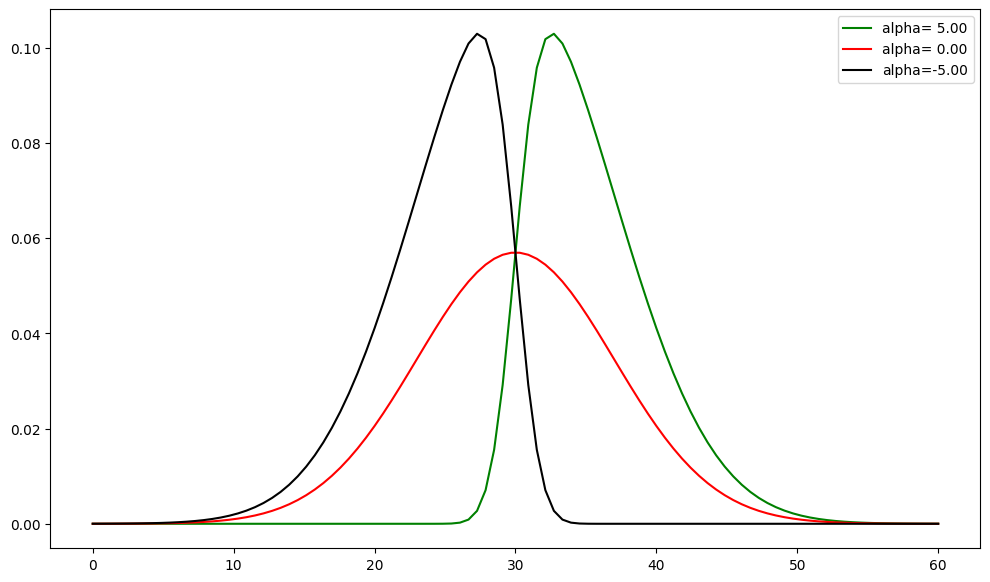

In [12]:
# Các phân phối chuẩn lệch mô phỏng với các tham số hình dạng khác nhau
plt.figure(figsize=(12, 7))
x = np.linspace(0, 60, 100)

alpha = 5
plt.plot(
    x,
    stats.skewnorm.pdf(x, alpha, loc=30, scale=7),
    c="g",
    label="alpha= {:.2f}".format(alpha),
)

alpha = 0
plt.plot(
    x,
    stats.skewnorm.pdf(x, alpha, loc=30, scale=7),
    c="r",
    label="alpha= {:.2f}".format(alpha),
)

alpha = -5
plt.plot(
    x,
    stats.skewnorm.pdf(x, alpha, loc=30, scale=7),
    c="k",
    label="alpha={:.2f}".format(alpha),
)
plt.legend()
plt.show()

Theo Azzalini và Capitanio, nếu $X$ là biến ngẫu nhiên liên tục, hàm mật độ chuẩn lệch của nó như sau:

$$ f(x) = 2 \phi(X) \Phi(\alpha x) $$

Trong đó $\alpha$ là một tham số định trước

Và $$ \phi(x) = \frac{exp(-\frac{x^{2}}{2})}{\sqrt{2\pi }} $$

Và $$ \Phi(\alpha x) = \int_{-\infty }^{\alpha x} \phi(t) dt $$

$\phi(x)$ là hàm mật độ chuẩn tắc và $\Phi(\alpha x)$ là hàm phân phối (tích lũy) chuẩn tắc. $\alpha$ là **tham số hình dạng (shape parameter)**. Hình 4 cho thấy các phân phối chuẩn lệch với các $\alpha$ khác nhau. Đây là một số tính chất về $\alpha$:

> - Khi $\alpha = 0$, phân phối chuẩn lệch là phân phối chuẩn tắc (đường cong màu đỏ ở hình 4).
> - Khi $\alpha > 0$, phân phối chuẩn lệch là phân phối lệch phải (đường cong màu xanh lá ở hình 4).
> - Khi $\alpha < 0$, phân phối chuẩn lệch là phân phối lệch trái (đường cong màu đen ở hình 4).
> - Khi $|\alpha|$ tăng, đỉnh của phân phối sẽ dịch xa hơn về bên phải hoặc bên trái.

Phân phối chuẩn lệch và các họ phân phối liên quan nặng về tính toán toán học. Một điểm rắc rối là phân phối chuẩn lệch có hai cách biểu diễn tham số: **tham số trực tiếp** (DP) và **tham số tâm hóa** (CP). Chúng tồn tại do các phép tính tối ưu hóa hợp lý cực đại. Ta sẽ không đi vào chi tiết kỹ thuật này ở đây. Hãy nói về chúng là gì và ta cần chú ý gì khi dùng chúng với phân phối chuẩn lệch.

Giả sử biến ngẫu nhiên $X$ có phân phối chuẩn lệch với trung bình = $\mu$, độ lệch chuẩn = $\sigma$, độ lệch = $\gamma _{1}$, ta có thể ký hiệu $X$ như sau:

**Phương pháp tham số tâm hóa (CP)**:

$$ X \sim SN(\mu,\sigma,\gamma_{1}) $$ 

Trong đó  $-0.995 < \gamma_{1} < 0.995$

**Phương pháp tham số trực tiếp (DP)**:

$$ X \sim SN(\xi, \omega, \alpha ) $$

Trong đó $\xi$ là tham số vị trí, $\omega$ là tham số thang đo và $\alpha$ là tham số hình dạng

Hầu hết các ứng dụng thống kê đều có hàm chuyển tham số tâm hóa sang tham số trực tiếp và ngược lại. Do đó, bạn không cần chuyển đổi bằng tay. Ta quen thuộc hơn với các thành phần trong phương pháp tham số tâm hóa và cách diễn giải của chúng. Bạn luôn có thể bắt đầu từ CP rồi dùng ứng dụng đã chọn để chuyển chúng sang DP. Trước khi dùng bất kỳ hàm phân phối chuẩn lệch nào với ứng dụng thống kê đã chọn, hãy chắc chắn bạn hiểu hàm nhận dạng đầu vào nào (CP hay DP).

<div class="alert alert-info">
    
**LƯU Ý:** Các ví dụ minh họa cho phần thứ hai của bài này được thực hiện bằng các gói phần mềm R, vì vậy ảnh chụp mã R và kết quả được đưa vào đây.
   </div>

### **3.2 Lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm và phân phối chuẩn lệch**

Ở phần trước ta đã nói về những điều cơ bản của phân phối chuẩn lệch. Bây giờ hãy áp dụng phương pháp này vào dữ liệu lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm của ta. Dữ liệu kéo dài từ đầu năm 2016 đến cuối năm 2021. Đây là một số thống kê từ dữ liệu.

**Hình 5: Các thống kê chính của lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm**

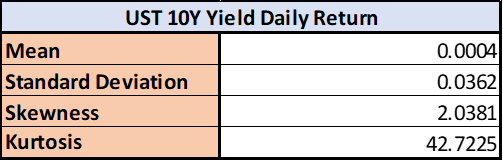

**Hình 6: Biểu đồ QQ phân phối chuẩn so với lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm**

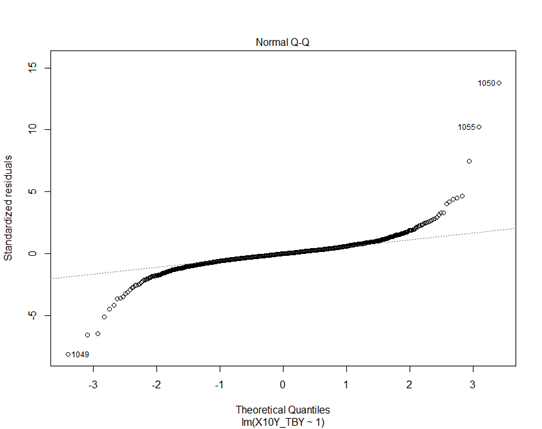

Từ hình 5, ta thấy lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm lệch phải và có đuôi dày. Hình 6 cũng cho thấy lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm có đuôi dày ở cả hai đầu so với phân phối chuẩn. Do đó, phân phối chuẩn không phải là lựa chọn tốt để mô tả biến này.

Bây giờ hãy thử phân phối chuẩn lệch trên lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm để xem phân phối có khớp dữ liệu không. Hình 7 cho thấy kết quả.

**Hình 7: Biểu đồ QQ phân phối chuẩn lệch so với lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm**

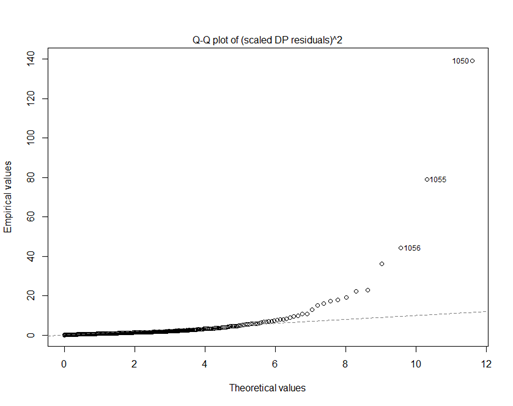

Từ hình 7, ta thấy phân phối chuẩn lệch khớp dữ liệu tốt hơn ở phía bên trái của đồ thị. Tuy nhiên, vẫn còn một số điểm ngoại lai lớn ở phía bên phải mà phân phối chuẩn lệch không nắm bắt được.

Bây giờ hãy tiến hành chạy một hồi quy đơn giản để hiểu tác động của lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones lên lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm. Biến phụ thuộc của ta sẽ là lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm và biến độc lập của ta sẽ là lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones. Ta sẽ chạy một mô hình hồi quy đơn giản với thiết lập biến phụ thuộc chuẩn và một mô hình với thiết lập biến phụ thuộc chuẩn lệch. Sau đó ta so sánh các biểu đồ QQ của phần dư tương ứng. Hình 8 cho thấy kết quả mô hình bình phương tối thiểu thông thường.

**Hình 8: Kết quả mô hình bình phương tối thiểu**

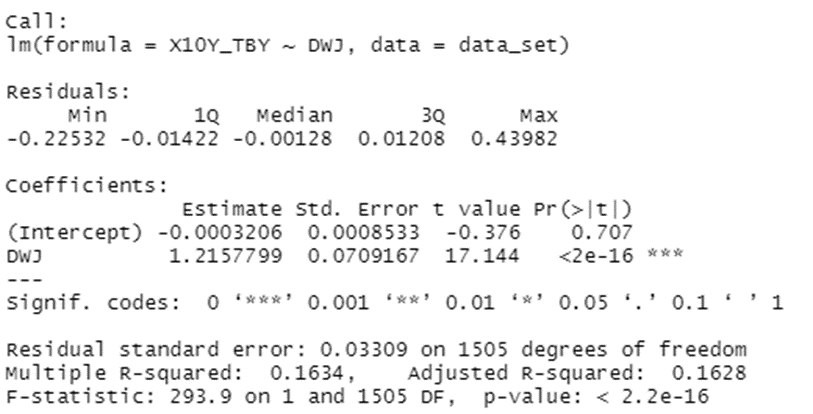

**Hình 9: Kết quả hồi quy chuẩn lệch**

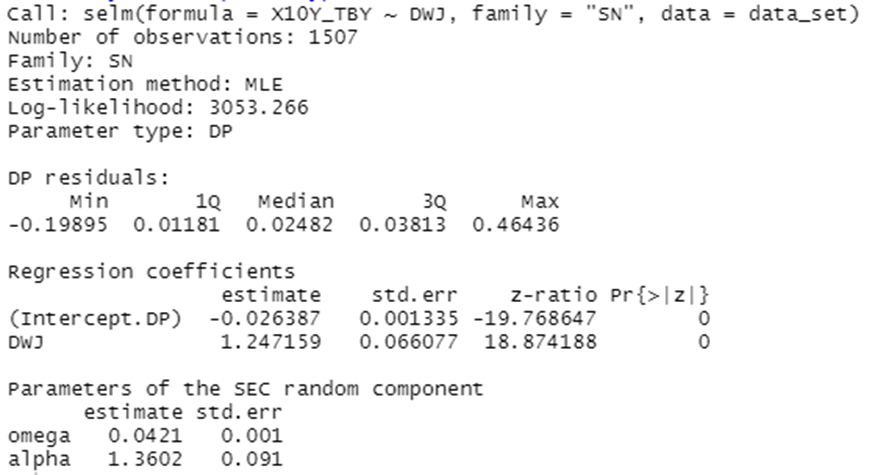

Từ các hình 8 và 9, ta thấy hệ số của lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones từ hồi quy bình phương tối thiểu của ta là 1,216 và từ hồi quy chuẩn lệch là 1,247. Alpha từ hồi quy chuẩn lệch là 1,36, nghĩa là biến phụ thuộc lệch phải. Bây giờ, hãy so sánh các biểu đồ QQ từ hồi quy bình phương tối thiểu và hồi quy chuẩn lệch của ta.

**Hình 10: Biểu đồ QQ cho phần dư từ hồi quy chuẩn và cho phần dư từ hồi quy chuẩn lệch**

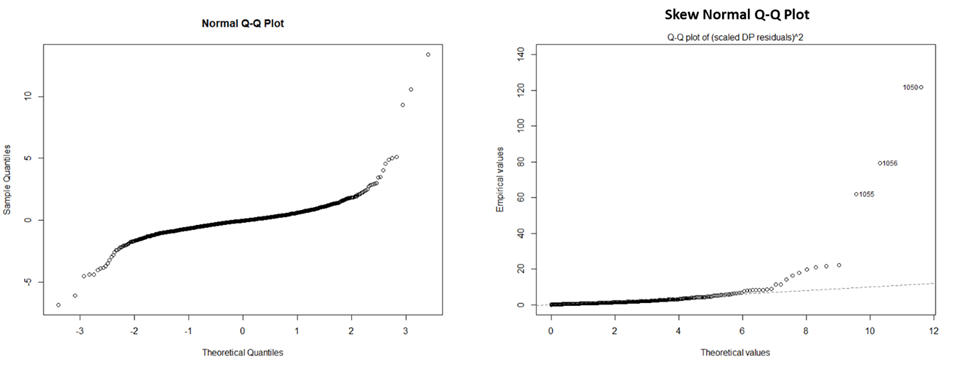

Hình 10 cho thấy các biểu đồ QQ cho phần dư của hai mô hình. Thang đo của hai biểu đồ QQ khác nhau do điều chỉnh CP-DP trong phân phối chuẩn lệch. Cách diễn giải vẫn như cũ. Từ biểu đồ QQ chuẩn (bình phương tối thiểu) bên trái, ta thấy dữ liệu đều cong ở cả hai đầu của đồ thị. Chỉ phần giữa theo một đường thẳng. Tuy nhiên, biểu đồ QQ chuẩn lệch bên phải có vẻ khớp tốt hơn. Đầu bên trái của dữ liệu cũng khớp tốt với đường thẳng. Chỉ ở bên phải của đồ thị ta thấy dữ liệu cong lên. Ta thấy hiện tượng này vì dữ liệu thực tế có đuôi phải dày hơn phân phối chuẩn. Ở phần tiếp theo, ta sẽ giới thiệu phân phối skew-t để có thể xử lý các đuôi dày hơn.

### **3.3 Những điều cơ bản của phân phối Skew-t**

Phân phối skew-t giống như phân phối t của Student với sự linh hoạt để điều chỉnh độ dày của đuôi. Phân phối t của Student là phân phối đối xứng có đuôi dày hơn phân phối chuẩn. Thường phân phối t của Student được dùng khi phân phối dữ liệu đối xứng nhưng đuôi dày hơn hoặc dài hơn phân phối chuẩn. Trong phần này, ta sẽ giới thiệu một phân phối giống phân phối t của Student nhưng có thể xử lý cả độ lệch và độ nhọn. Đó là phân phối skew-t.

**Hình 11: Các phân phối skew-t mô phỏng với các bậc tự do khác nhau**

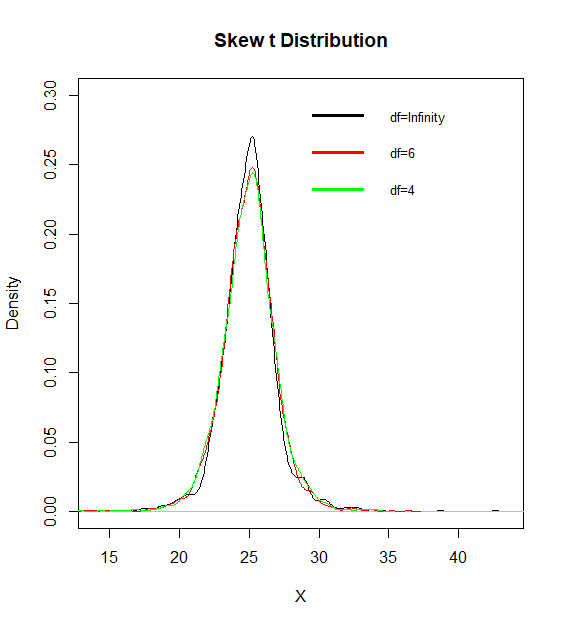

Nếu X là biến ngẫu nhiên liên tục, hàm mật độ skew-t của nó như sau:

$2t(X;\nu )T(\alpha X;\nu )$

Trong đó $\nu$ là bậc tự do

Và $ t(X;\nu )$ là hàm mật độ xác suất của phân phối t của Student

Và $ T(\alpha X;\nu )$ là hàm phân phối xác suất tích lũy của phân phối t của Student.

Hình 11 cho thấy ba phân phối skew-t với các bậc tự do khác nhau. Bậc tự do là một tham số của phân phối skew-t để điều chỉnh độ dày của đuôi. Khi bậc tự do tăng, đỉnh của phân phối gầy đi và đuôi dày hơn. Đây là một số tính chất của phân phối skew-t:

Khi $\alpha$ =0, phân phối skew-t rút gọn thành phân phối t của Student.

Khi $ \nu\to \infty $, phân phối skew-t rút gọn thành phân phối chuẩn lệch.

Khi $\alpha$ =0 và $ \nu\to \infty $, phân phối skew-t rút gọn thành phân phối chuẩn tắc.

Tương tự phân phối chuẩn lệch, phân phối skew-t cũng có điều chỉnh chuyển đổi CP-DP. Hãy xem CP và DP của phân phối skew-t. Giả sử biến ngẫu nhiên X có phân phối skew-t với trung bình = $\mu$, độ lệch chuẩn = $\sigma$, độ lệch = $\gamma _{1}$ và độ nhọn = $\gamma_{2}$, và ta có thể ký hiệu X như sau:

Phương pháp tham số tâm hóa (CP): $ X\sim ST(\mu ,\sigma ,\gamma _{1},\gamma_{2})$ 

Trong đó $\gamma _{1}$ < 0.995

Phương pháp tham số trực tiếp (DP): $X\sim ST(\xi ,\omega ,\alpha,\nu )$

Trong đó $\xi$ là tham số vị trí, $\omega$ là tham số thang đo, $\alpha$ là tham số hình dạng và $\nu$ là bậc tự do

Mọi ứng dụng thống kê đều có thể chuyển CP sang DP và ngược lại cho phân phối skew-t.

### **3.4 Lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm và phân phối Skew-t**

Ở phần trước, ta đã thử dùng phân phối chuẩn lệch để khớp dữ liệu lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm. Tuy nhiên, phân phối chuẩn lệch không mô tả tốt bản chất đuôi phải dày của dữ liệu lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm. Trong phần này, hãy thử phân phối skew-t để xem phân phối này có làm tốt hơn không.

**Hình 12: Biểu đồ QQ phân phối skew-t so với lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm**

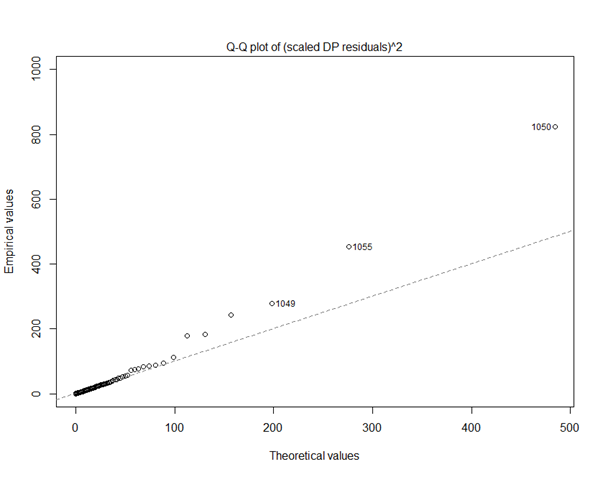

Từ hình 12, ta thấy nhiều điểm dữ liệu nằm trên đường thẳng hơn ở biểu đồ QQ phân phối skew-t so với biểu đồ QQ phân phối chuẩn lệch ở Hình 7. Phân phối skew-t khớp dữ liệu lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm tốt hơn phân phối chuẩn lệch. Có ít điểm dữ liệu không nằm trên đường thẳng hơn với phân phối skew-t.

Bây giờ hãy chạy hồi quy phân phối skew-t của lợi suất theo ngày của lợi suất trái phiếu kho bạc Mỹ 10 năm theo lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones. Hình 13 cho thấy kết quả từ hồi quy phân phối skew-t.

**Hình 13: Kết quả hồi quy phân phối skew-t**

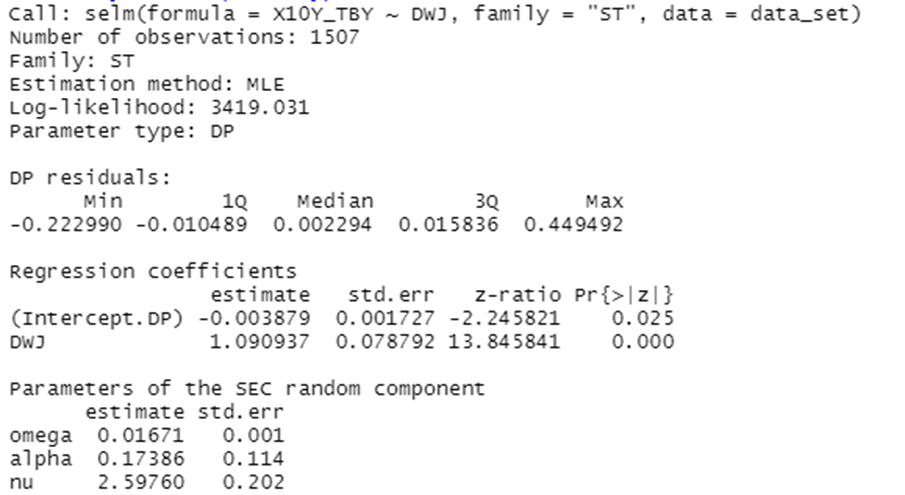

**Hình 14: Biểu đồ QQ cho phần dư từ hồi quy chuẩn lệch và cho phần dư từ hồi quy skew-t**

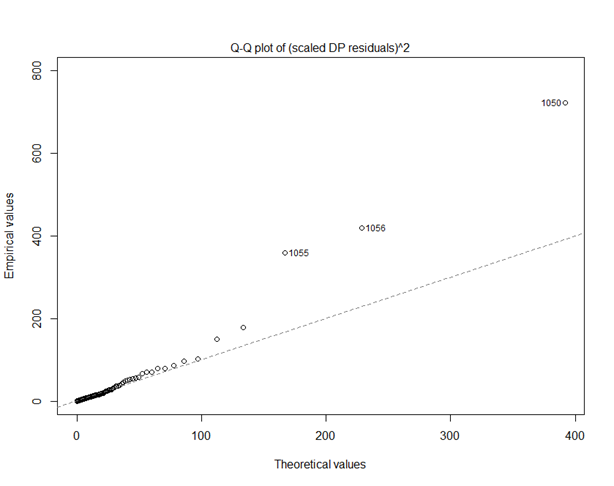

Từ Hình 14, ta thấy phân phối skew-t có độ khớp hồi quy tốt hơn cho phía bên phải của biểu đồ QQ phần dư hồi quy so với hồi quy phân phối chuẩn lệch. Ngoài ra, hệ số của lợi suất theo ngày của Chỉ số Công nghiệp Dow Jones nhỏ hơn nhiều (1,091 từ hình 13) so với phân phối chuẩn lệch. Đây là bằng chứng thêm rằng ta nên mô hình hóa đúng đuôi dày hơn của dữ liệu nền.

## **4. Kết luận**

Trong bài này, ta đã bàn về độ lệch và độ nhọn là gì. Ta nói về các dạng của độ lệch và cách đo nó. Ta cũng nói về các dạng của độ nhọn và cách đo nó. Dựa trên kiến thức về độ lệch và độ nhọn, ta giới thiệu phân phối chuẩn lệch và phân phối skew-t để xử lý bộ dữ liệu giống phân phối chuẩn nhưng có độ lệch và đuôi dày. Ta đi qua những điều cơ bản của phân phối chuẩn lệch và phân phối skew-t. Sau đó ta áp dụng các phân phối này vào ví dụ lợi suất trái phiếu kho bạc Mỹ và chỉ số chứng khoán Mỹ của ta. Ở bài tiếp theo, ta sẽ khám phá các chỉ số tính quan hệ giữa các biến ngẫu nhiên.

---

## **Tài liệu tham khảo**

- Azzalini, Adelchi, and Antonella Capitanio. The Skew-Normal and Related Families. Cambridge University Press, IMS Monographs Series, 2014.